# Student Productivity Prediction — Flask TP
Goal: predict `productivity_score` (regression) from student habits, then deploy the best model in a Flask app.

## 1. Load the data

In [1]:
import pandas as pd, numpy as np, joblib, warnings
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

train = pd.read_csv('data/train.csv')
test  = pd.read_csv('data/test.csv')
print(train.shape, test.shape)
train.head()

(16000, 19) (4000, 18)


,id,student_id,age,gender,study_hours_per_day,sleep_hours,phone_usage_hours,social_media_hours,youtube_hours,gaming_hours,breaks_per_day,coffee_intake_mg,exercise_minutes,assignments_completed,attendance_percentage,stress_level,focus_score,final_grade,productivity_score
0,5894,5895,28,Other,4.56,7.61,1.70,7.23,3.80,3.18,2,256,102,14,52.72,6,68,70.48,55.29
1,3728,3729,18,Female,7.95,8.17,4.24,5.50,4.80,3.53,9,370,115,17,87.51,1,69,57.67,78.68
2,8958,8959,19,Male,6.06,9.02,3.17,5.08,5.09,3.74,5,250,33,9,72.39,8,57,72.51,60.66
3,7671,7672,21,Female,1.40,8.06,2.35,1.03,0.13,5.23,4,55,110,0,87.47,5,34,81.93,37.51
4,5999,6000,25,Male,9.27,7.39,10.68,5.21,3.43,5.38,11,436,66,17,47.66,5,37,49.11,50.72


`test.csv` has **no** `productivity_score` (it is for a Kaggle-style submission), so we evaluate our models with a hold-out split taken from `train.csv`.

## 2. Data preparation (missing values, duplicates, identifiers)

In [2]:
print('Missing values:', train.isna().sum().sum())
print('Duplicated rows (without ids):', train.drop(columns=['id','student_id']).duplicated().sum())
print(train.gender.value_counts())
train.describe().T

Missing values: 0
Duplicated rows (without ids): 0
gender
Male      7704
Female    7683
Other      613
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
id,16000.0,10006.506875,5790.786923,1.0,4993.7500,10020.500,15029.2500,19999.00
student_id,16000.0,10007.506875,5790.786923,2.0,4994.7500,10021.500,15030.2500,20000.00
age,16000.0,23.020937,3.753283,17.0,20.0000,23.000,26.0000,29.00
study_hours_per_day,16000.0,5.254446,2.743874,0.5,2.8900,5.250,7.6325,10.00
sleep_hours,16000.0,6.515254,2.033761,3.0,4.7600,6.520,8.3200,10.00
phone_usage_hours,16000.0,6.258693,3.305756,0.5,3.3900,6.230,9.1000,12.00
social_media_hours,16000.0,3.995989,2.311722,0.0,2.0000,3.990,5.9700,8.00
youtube_hours,16000.0,2.985526,1.731141,0.0,1.4800,2.970,4.4800,6.00
gaming_hours,16000.0,2.976373,1.733127,0.0,1.4775,2.950,4.4900,6.00
breaks_per_day,16000.0,7.539625,4.017236,1.0,4.0000,8.000,11.0000,14.00


No missing values and no duplicates. `id` and `student_id` are only identifiers (`student_id = id + 1`), so we drop them: they carry no information about productivity. We still keep an imputer in the pipeline so the app is safe if a value is ever missing.

count    16000.000000
mean        50.146637
std         16.095733
min          0.000000
25%         38.657500
50%         50.220000
75%         61.840000
max        100.000000
Name: productivity_score, dtype: float64


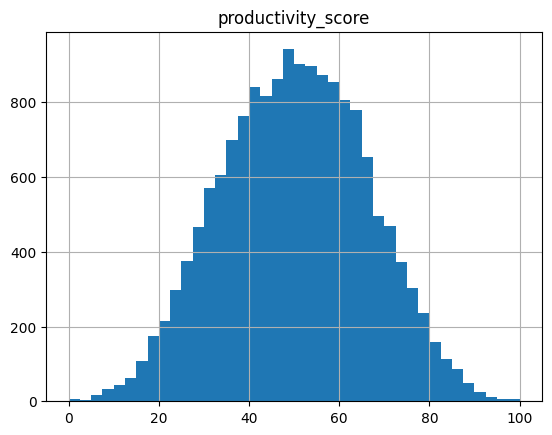

In [3]:
y = train['productivity_score']
X = train.drop(columns=['id','student_id','productivity_score'])
print(y.describe())
y.hist(bins=40); plt.title('productivity_score'); plt.show()

## 3. Most relevant characteristics (feature selection)

In [4]:
corr = train.drop(columns=['id','student_id']).corr(numeric_only=True)['productivity_score'].drop('productivity_score')
print(corr.sort_values(key=abs, ascending=False).round(3))

study_hours_per_day      0.732
focus_score              0.415
sleep_hours              0.339
phone_usage_hours       -0.327
stress_level            -0.196
attendance_percentage    0.175
coffee_intake_mg         0.020
breaks_per_day          -0.007
assignments_completed    0.005
age                     -0.004
youtube_hours            0.002
exercise_minutes         0.002
gaming_hours             0.001
final_grade              0.000
social_media_hours       0.000
Name: productivity_score, dtype: float64

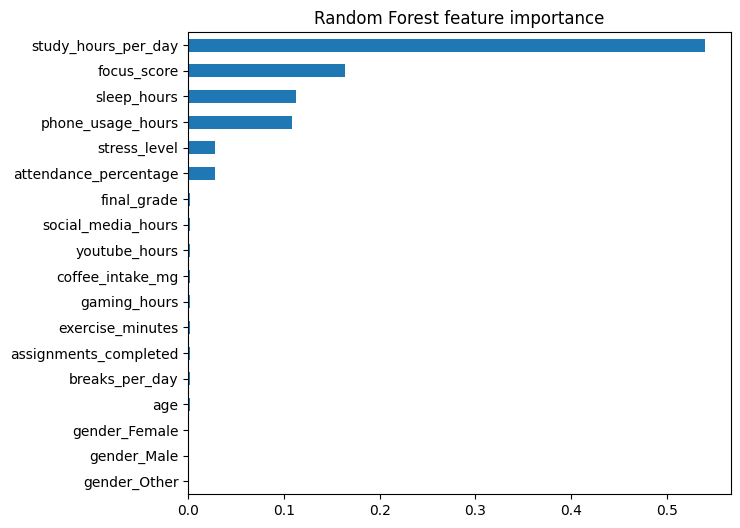

study_hours_per_day      0.5399
focus_score              0.1638
sleep_hours              0.1130
phone_usage_hours        0.1088
stress_level             0.0277
attendance_percentage    0.0277
final_grade              0.0023
social_media_hours       0.0023
youtube_hours            0.0023
coffee_intake_mg         0.0023
gaming_hours             0.0023
exercise_minutes         0.0022
assignments_completed    0.0018
breaks_per_day           0.0016
age                      0.0015
gender_Female            0.0003
gender_Male              0.0003
gender_Other             0.0001
dtype: float64

In [5]:
from sklearn.ensemble import RandomForestRegressor
Xd = pd.get_dummies(X, columns=['gender'])
rf = RandomForestRegressor(300, random_state=42, n_jobs=-1).fit(Xd, y)
imp = pd.Series(rf.feature_importances_, Xd.columns).sort_values()
imp.plot(kind='barh', figsize=(7,6), title='Random Forest feature importance'); plt.show()
imp.sort_values(ascending=False).round(4)

Two independent methods (correlation and random-forest importance) agree: only **6 features** matter — `study_hours_per_day`, `focus_score`, `sleep_hours`, `phone_usage_hours`, `stress_level`, `attendance_percentage`. All the others have importance ≈ 0 (about 0.002 each, which is just noise). Keeping 6 features also gives a short, usable web form.

In [6]:
FEATURES = ['study_hours_per_day','sleep_hours','phone_usage_hours','stress_level','focus_score','attendance_percentage']
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression
cv = KFold(5, shuffle=True, random_state=42)
print('R2, all features     :', cross_val_score(LinearRegression(), Xd, y, cv=cv, scoring='r2').mean().round(4))
print('R2, 6 chosen features:', cross_val_score(LinearRegression(), X[FEATURES], y, cv=cv, scoring='r2').mean().round(4))

R2, all features     : 1.0
R2, 6 chosen features: 1.0


Using only the 6 features loses nothing compared with using all the columns.

## 4. Compare several models

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

X6 = X[FEATURES]
X_train, X_test, y_train, y_test = train_test_split(X6, y, test_size=0.2, random_state=42)

def make(model):
    return Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('model', model)])

models = {
    'Linear Regression': make(LinearRegression()),
    'Ridge':             make(Ridge(alpha=1.0)),
    'Decision Tree':     make(DecisionTreeRegressor(random_state=42)),
    'KNN':               make(KNeighborsRegressor(n_neighbors=7)),
    'Random Forest':     make(RandomForestRegressor(200, random_state=42, n_jobs=-1)),
    'Gradient Boosting': make(GradientBoostingRegressor(random_state=42)),
}
rows = []
for name, pipe in models.items():
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='r2').mean()
    pipe.fit(X_train, y_train); p = pipe.predict(X_test)
    rows.append([name, cv_r2, r2_score(y_test,p), mean_absolute_error(y_test,p), mean_squared_error(y_test,p)**.5])
results = pd.DataFrame(rows, columns=['Model','CV R2','Test R2','Test MAE','Test RMSE']).sort_values('Test RMSE')
results.round(4)

,Model,CV R2,Test R2,Test MAE,Test RMSE
0,Linear Regression,1.0000,1.0000,0.0025,0.0029
1,Ridge,1.0000,1.0000,0.0027,0.0032
5,Gradient Boosting,0.9911,0.9914,1.1914,1.5037
4,Random Forest,0.9791,0.9806,1.7805,2.2564
3,KNN,0.9794,0.9804,1.7680,2.2688
2,Decision Tree,0.9141,0.9191,3.6924,4.6098


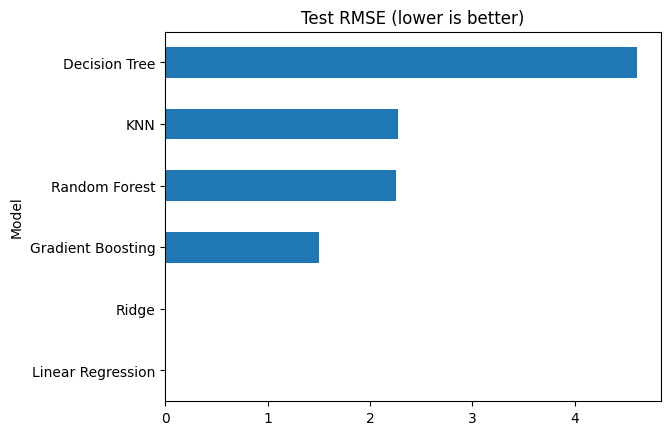

In [8]:
results.set_index('Model')['Test RMSE'].plot(kind='barh', title='Test RMSE (lower is better)'); plt.show()

**Result.** Linear Regression (and Ridge) reach R² ≈ 1.000 with an error of about 0.003 points, far better than the tree-based models (RMSE 1.5 to 4.6). This means productivity is (almost exactly) a *linear* combination of the 6 features, so a simple model is the best choice here. It is also the fastest, the smallest to deploy, and easy to interpret.

## 5. Best model and its equation

In [9]:
best_name = results.iloc[0]['Model']
print('Best model:', best_name)
best = models[best_name]
# retrain on ALL the training data before saving
best.fit(X6, y)
lin = LinearRegression().fit(X6, y)
print('Intercept:', round(lin.intercept_,3))
print(pd.Series(lin.coef_, FEATURES).round(3))

Best model: Linear Regression
Intercept: -6.239
study_hours_per_day      4.316
sleep_hours              2.698
phone_usage_hours       -1.619
stress_level            -1.079
focus_score              0.324
attendance_percentage    0.162
dtype: float64


Reading the coefficients: +1 study hour gives about +4.3 points, +1 sleep hour about +2.7, +1 phone hour about −1.6, +1 stress level about −1.1, +1 focus point about +0.32, and +1 attendance point about +0.16.

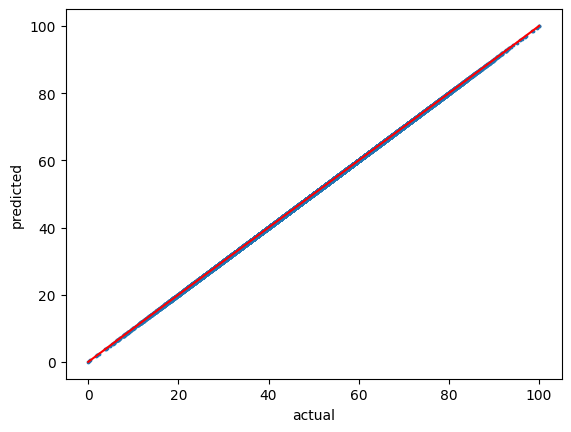

In [10]:
y_pred = np.clip(best.predict(X6), 0, 100)
plt.scatter(y, y_pred, s=3); plt.plot([0,100],[0,100],'r'); plt.xlabel('actual'); plt.ylabel('predicted'); plt.show()

## 6. Save the model for Flask

In [11]:
joblib.dump(best, 'model.pkl')
import json; json.dump(FEATURES, open('features.json','w'))
print(joblib.load('model.pkl').predict(pd.DataFrame([[6,7,4,5,65,75]], columns=FEATURES)))

[59.85590146]


## 7. Predictions for `test.csv` (submission file)

In [12]:
pred = np.clip(best.predict(test[FEATURES]), 0, 100)
sub = pd.DataFrame({'id': test['id'], 'productivity_score': pred.round(2)})
sub.to_csv('submission.csv', index=False)
sub.head()

,id,productivity_score
0,10650,49.95
1,2041,90.88
2,8668,60.03
3,1114,50.36
4,13902,35.69
